# 02 · Exploratory Data Analysis (EDA)

**Câu hỏi nghiên cứu chính:** Vì sao Messi ghi ít bàn hơn hẳn ở Ligue 1 (PSG) so với La Liga (Barcelona)?
Do **ít cơ hội hơn** (ít cú sút, xG thấp) hay do **dứt điểm kém hơn** (ghi ít hơn xG)? Và có phải **chỉ do tuổi** không?

**Dữ liệu dùng trong notebook** (StatsBomb Open Data, tạo bởi `fetch_sb.py` → `clean_sb.py`)

| File | Mỗi dòng là | Dùng cho |
|---|---|---|
| `data/clean/messi_league_matches.csv` | 1 trận Messi ra sân | Mọi chỉ số theo trận, theo 90 phút, theo xG |
| `data/clean/messi_league_shots.csv` | 1 cú sút của Messi | Chất lượng cú sút, vị trí sút, kết quả cú sút |

**Ba giai đoạn so sánh.** Messi ở PSG đã 34–35 tuổi, nên ngoài toàn bộ thời gian ở Barca, notebook tách
riêng **giai đoạn cuối ở Barca (2018–21)** làm mốc so sánh công bằng hơn về tuổi:
`Barca 2004-18`, `Barca 2018-21`, `PSG 2021-23`.

**Mỗi mục phục vụ giả thuyết nào** (danh sách giả thuyết ở mục 6)

| Mục | Giả thuyết |
|---|---|
| 2. Phân phối số bàn và số cú sút mỗi trận | H2 |
| 3. Xu hướng theo mùa | H4 |
| 4. So sánh ba giai đoạn | H1, H2, H3 |
| 5. Chất lượng cú sút và hiệu quả dứt điểm | H1, H3 |

## 0. Thiết lập

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The project root is the first folder above here that contains src/eda_utils.py.
PROJECT_ROOT = next(
    folder for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (folder / "src" / "eda_utils.py").exists()
)
sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_utils import (
    # constants
    LATE_BARCA_FIRST_SEASON, MIN_SEASON_MINUTES, PERIOD_ORDER, LEAGUE_ORDER, PERIOD_METRICS,
    PERIOD_COLORS, LEAGUE_COLORS, SECOND_SERIES_COLOR, GOAL_COLOR, MISS_COLOR, TEXT_SECONDARY, GRID_COLOR,
    AXIS_COLOR, PENALTY_BOX, PITCH_VIEW_START,
    # helpers
    apply_plot_style, load_data, season_start_year, summarize, compare_periods, share_table,
    count_shares, plot_grouped_shares, plot_shot_map,
)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
apply_plot_style()

## 1. Tổng quan dữ liệu

In [2]:
matches, shots = load_data(PROJECT_ROOT)

print(f"Thư mục dự án: {PROJECT_ROOT.name}")
print(f"Trận: {len(matches)} | Cú sút: {len(shots)} | Bàn thắng: {matches['goals'].sum()}")

for name, table in [("trận", matches), ("cú sút", shots)]:
    missing = table.isna().sum()
    print(f"Ô trống trong bảng {name}:", "không có" if missing.sum() == 0 else missing[missing > 0].to_dict())

Thư mục dự án: project
Trận: 577 | Cú sút: 2570 | Bàn thắng: 494
Ô trống trong bảng trận: không có
Ô trống trong bảng cú sút: không có


In [3]:
overview = summarize(matches, "competition")
display(overview[["matches", "starts", "minutes", "goals", "np_goals", "shots", "npxg"]])

penalties = (
    shots[shots["is_penalty"]]
    .groupby("competition")["is_goal"]
    .agg(penalties="size", scored="sum")
    .reindex(LEAGUE_ORDER, fill_value=0)
)
print("Penalty Messi thực hiện:")
display(penalties)

,matches,starts,minutes,goals,np_goals,shots,npxg
competition,,,,,,,
LaLiga,519,463,42093,472,412,2352,265.542
Ligue 1,58,56,4991,22,22,218,23.130


Penalty Messi thực hiện:


,penalties,scored
competition,,
LaLiga,74,60
Ligue 1,0,0


> **Ghi chú dữ liệu.**
> - Số bàn trong StatsBomb đã được đối chiếu một lần với bộ dữ liệu bàn thắng trên Kaggle và khớp ở cả 577 trận.
>   StatsBomb Open Data thiếu trận Barcelona 4–1 Real Zaragoza (26/09/2007, Messi ghi 2 bàn), nên trận này nằm
>   ngoài phân tích.
> - **Messi không thực hiện quả penalty nào ở Ligue 1**, trong khi ở La Liga penalty chiếm 60/472 bàn. Vì vậy mọi
>   so sánh dùng chỉ số **không tính penalty** (npxG, bàn không pen).
> - Số phút bị giới hạn ở 90 (không tính bù giờ), nên các chỉ số /90' hơi cao hơn thực tế. Bù giờ có xu hướng dài
>   hơn ở các mùa gần đây, nên nếu có sai lệch thì nó làm các chỉ số /90' của PSG **trông tốt hơn** thực tế. Kết
>   luận "PSG thấp hơn" vì vậy là kết luận thận trọng.

In [4]:
period_summary = summarize(matches, "period")
display(period_summary[["matches", "minutes", "np_goals", "npxg", "np_goals_minus_npxg",
                        "shots_p90", "npxg_p90", "np_goals_p90", "npxg_per_shot", "np_conversion"]])

,matches,minutes,np_goals,npxg,np_goals_minus_npxg,shots_p90,npxg_p90,np_goals_p90,npxg_per_shot,np_conversion
period,,,,,,,,,,
Barca 2004-18,417,33477,333,216.024,116.976,4.912,0.581,0.895,0.122,0.188
Barca 2018-21,102,8616,79,49.518,29.482,5.484,0.517,0.825,0.097,0.155
PSG 2021-23,58,4991,22,23.130,-1.130,3.931,0.417,0.397,0.106,0.101


## 2. Phân phối số bàn và số cú sút mỗi trận (H2)

Chỉ xét **trận đá chính** để không bị lệch bởi các trận vào sân vài phút.

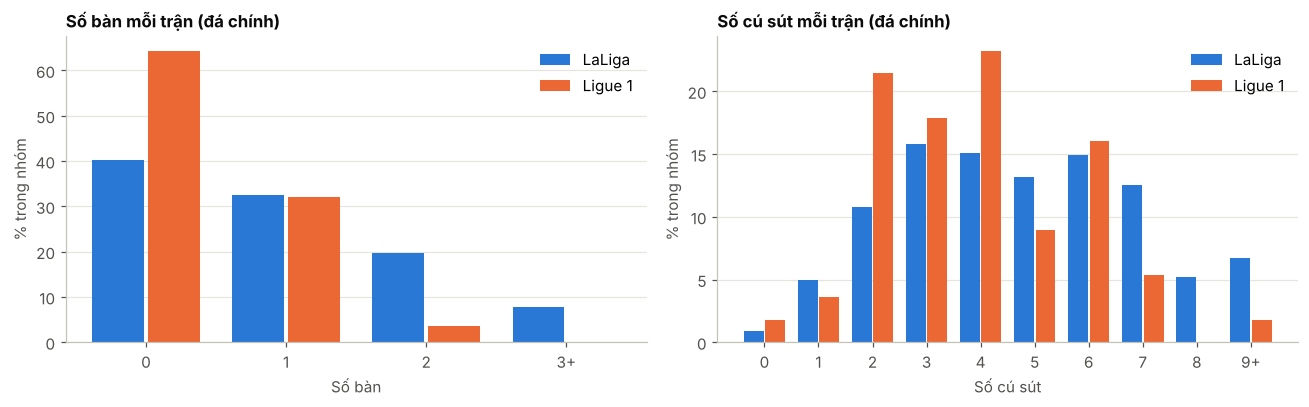

goals              shots               npxg             
             mean median   std  mean median   std  mean median   std
competition                                                         
LaLiga       0.96    1.0  0.98  4.86    5.0  2.37  0.55   0.46  0.43
Ligue 1      0.39    0.0  0.56  3.88    4.0  1.83  0.41   0.34  0.30

In [5]:
starts = matches[matches["started"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_grouped_shares(axes[0], count_shares(starts["goals"], starts["competition"], 3, LEAGUE_ORDER),
                    LEAGUE_COLORS, "Số bàn mỗi trận (đá chính)", "Số bàn")
plot_grouped_shares(axes[1], count_shares(starts["shots"], starts["competition"], 9, LEAGUE_ORDER),
                    LEAGUE_COLORS, "Số cú sút mỗi trận (đá chính)", "Số cú sút")
fig.tight_layout()
plt.show()

display(starts.groupby("competition")[["goals", "shots", "npxg"]].agg(["mean", "median", "std"]).round(2))

**Nhận xét**

- Ở Ligue 1, Messi **không ghi bàn trong khoảng 64% số trận đá chính**, so với khoảng 40% ở La Liga. Trận ghi từ 2 bàn trở lên chiếm khoảng 28% ở La Liga nhưng chỉ khoảng 4% ở Ligue 1 (2 trận).
- Số cú sút cũng dịch sang trái: trung vị **5 cú/trận ở La Liga, 4 cú ở Ligue 1**. Khoảng một phần tư số trận La Liga có từ 7 cú sút trở lên, trong khi ở Ligue 1 chỉ khoảng 7%.
- Số bàn và số cú sút là **dữ liệu đếm, lệch phải, nhiều số 0**. Khi kiểm định, nên dùng hồi quy Poisson hoặc Negative Binomial thay vì t-test trên trung bình.

## 3. Xu hướng theo mùa (H4)

Bỏ khỏi biểu đồ (dưới 900 phút): ['2004-05']


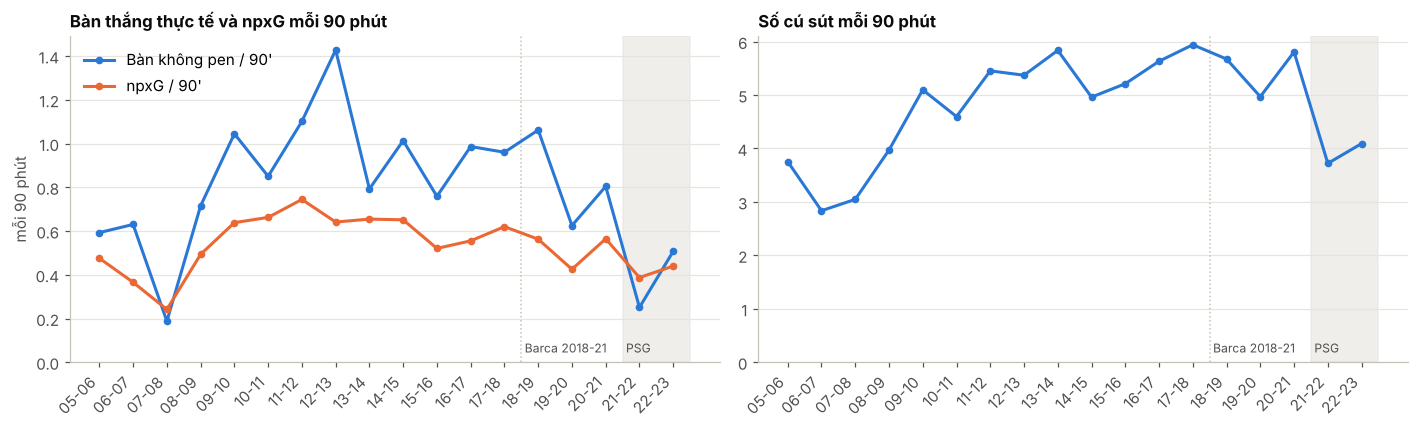

,minutes,np_goals_p90,npxg_p90,shots_p90,npxg_per_shot
season,,,,,
2005-06,911,0.593,0.476,3.754,0.127
2006-07,2000,0.630,0.366,2.835,0.129
2007-08,1920,0.188,0.241,3.047,0.084
2008-09,2517,0.715,0.493,3.969,0.129
2009-10,2843,1.045,0.638,5.097,0.126
2010-11,2859,0.850,0.662,4.596,0.148
2011-12,3269,1.101,0.744,5.451,0.145
2012-13,2648,1.427,0.641,5.370,0.122
2013-14,2499,0.792,0.655,5.834,0.117


In [6]:
season_table = summarize(matches, ["season", "competition"]).reset_index().sort_values("season")
too_short = season_table["minutes"] < MIN_SEASON_MINUTES
print("Bỏ khỏi biểu đồ (dưới", MIN_SEASON_MINUTES, "phút):", season_table.loc[too_short, "season"].tolist())
trend = season_table[~too_short].reset_index(drop=True)

x = np.arange(len(trend))
season_labels = [s[2:] for s in trend["season"]]          # '2018-19' -> '18-19'
late_barca_x = trend.index[trend["season"].map(season_start_year) == LATE_BARCA_FIRST_SEASON][0]
psg_x = trend.index[trend["competition"] == "Ligue 1"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
for ax in axes:
    ax.axvspan(psg_x.min() - 0.5, psg_x.max() + 0.5, color=GRID_COLOR, alpha=0.6, zorder=0)
    ax.axvline(late_barca_x - 0.5, color=AXIS_COLOR, linestyle=":", linewidth=1)
    ax.set_xticks(x, season_labels, rotation=45, ha="right")
    ax.grid(axis="x", visible=False)

ax = axes[0]
ax.plot(x, trend["np_goals_p90"], color=GOAL_COLOR, marker="o", markersize=4, label="Bàn không pen / 90'")
ax.plot(x, trend["npxg_p90"], color=SECOND_SERIES_COLOR, marker="o", markersize=4, label="npxG / 90'")
ax.set_title("Bàn thắng thực tế và npxG mỗi 90 phút")
ax.set_ylabel("mỗi 90 phút")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(x, trend["shots_p90"], color=GOAL_COLOR, marker="o", markersize=4)
ax.set_title("Số cú sút mỗi 90 phút")
ax.set_ylim(bottom=0)

for ax in axes:
    bottom_label_y = ax.get_ylim()[1] * 0.03
    ax.text(late_barca_x - 0.4, bottom_label_y, "Barca 2018-21", fontsize=8, color=TEXT_SECONDARY)
    ax.text(psg_x.min() - 0.4, bottom_label_y, "PSG", fontsize=8, color=TEXT_SECONDARY)
fig.tight_layout()
plt.show()

display(trend.set_index("season")[["minutes", "np_goals_p90", "npxg_p90", "shots_p90", "npxg_per_shot"]])

**Nhận xét**

- Từ mùa 2008-09 đến 2020-21, đường bàn thắng **gần như luôn nằm trên đường npxG**, nghĩa là Messi ghi nhiều hơn mức kỳ vọng ở hầu hết các mùa. Đỉnh là mùa 2012-13: 1,43 bàn/90' so với npxG 0,64.
- Ở PSG, khoảng cách này **biến mất**: mùa 2021-22 ghi thấp hơn xG (0,25 so với 0,39), mùa 2022-23 chỉ cao hơn một chút (0,51 so với 0,44).
- **Số cú sút/90' giảm mạnh nhất sự nghiệp khi sang PSG**: từ khoảng 5–6 cú (2011–2021) xuống 3,7–4,1 cú.
- npxG/90' ở PSG (0,39–0,44) **không quá khác** mùa 2019-20 ở Barca (0,43). Vậy mức sụt bàn thắng không chỉ do cơ hội.
- Mùa 2007-08 thấp bất thường một phần vì thiếu trận 26/09/2007 (Messi ghi 2 bàn) trong dữ liệu StatsBomb.

## 4. So sánh ba giai đoạn (H1–H3)

Thanh lỗi là **khoảng tin cậy 95% bằng bootstrap** (lấy mẫu lại theo trận). Đây là mô tả trong EDA,
chưa phải kiểm định: hai khoảng chồng nhau chưa chắc là không khác biệt, và ngược lại.

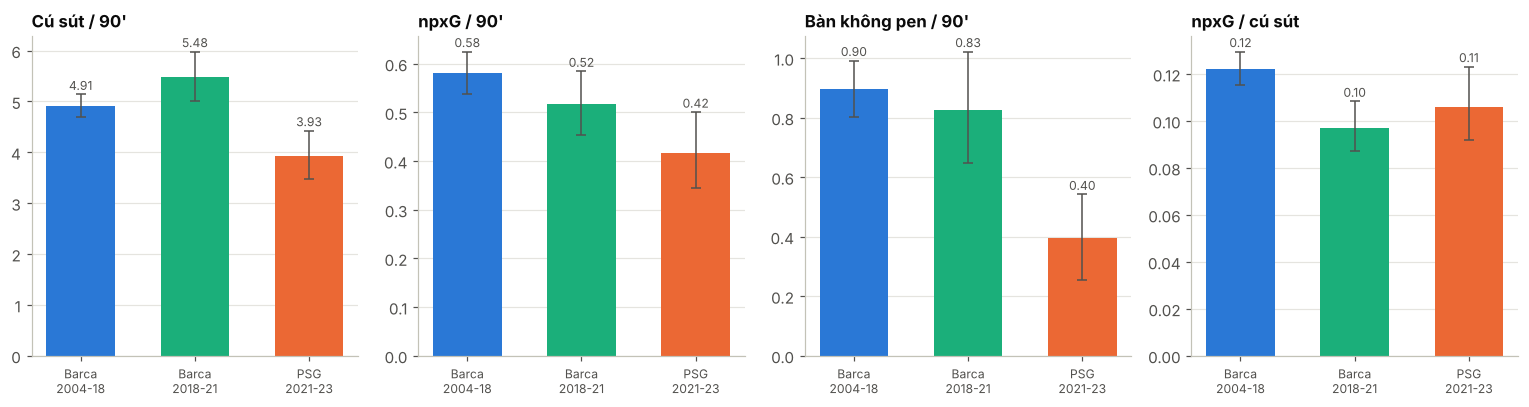

period,Barca 2004-18,Barca 2018-21,PSG 2021-23
metric,,,
Bàn không pen / 90',0.895,0.825,0.397
Cú sút / 90',4.912,5.484,3.931
npxG / 90',0.581,0.517,0.417
npxG / cú sút,0.122,0.097,0.106


In [7]:
comparison = compare_periods(matches)

fig, axes = plt.subplots(1, len(PERIOD_METRICS), figsize=(14, 3.8))
for ax, (_, label, *_rest) in zip(axes, PERIOD_METRICS):
    rows = comparison[comparison["metric"] == label].set_index("period").reindex(PERIOD_ORDER)
    positions = np.arange(len(rows))
    errors = [rows["value"] - rows["ci_low"], rows["ci_high"] - rows["value"]]
    bars = ax.bar(positions, rows["value"], width=0.6, color=[PERIOD_COLORS[p] for p in rows.index])
    ax.errorbar(positions, rows["value"], yerr=errors, fmt="none", ecolor=TEXT_SECONDARY, capsize=3, linewidth=1)
    for bar, high in zip(bars, rows["ci_high"]):
        ax.annotate(f"{bar.get_height():.2f}", (bar.get_x() + bar.get_width() / 2, high),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=TEXT_SECONDARY)
    ax.set_xticks(positions, [p.replace(" ", "\n") for p in rows.index], fontsize=8)
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

display(comparison.pivot(index="metric", columns="period", values="value").reindex(columns=PERIOD_ORDER))

**Nhận xét**

| Chỉ số | Barca 2018-21 → PSG | Ghi chú |
|---|---|---|
| Cú sút / 90' | 5,48 → 3,93 (**−28%**) | Hai khoảng tin cậy không chồng nhau |
| npxG / 90' | 0,52 → 0,42 (−19%) | Hai khoảng tin cậy chồng nhau |
| Bàn không pen / 90' | 0,83 → 0,40 (**−52%**) | Hai khoảng tin cậy không chồng nhau |
| npxG / cú sút | 0,097 → 0,106 | PSG **không thấp hơn** giai đoạn cuối ở Barca |

- **Chất lượng mỗi cú sút không giảm** ở PSG. Giai đoạn có xG/cú sút cao hẳn là Barca 2004-18, khi Messi trẻ và chơi gần khung thành hơn.
- Phân tách mức giảm 0,43 bàn/90' so với Barca 2018-21:
  - khoảng **0,10** đến từ việc npxG/90' giảm (ít cơ hội hơn, chủ yếu do sút ít hơn);
  - khoảng **0,33** đến từ việc mất phần vượt xG (từ +0,31/90' xuống −0,02/90').

  Tức là khoảng **3/4 mức giảm bàn thắng đến từ hiệu quả dứt điểm**, chỉ khoảng 1/4 đến từ số lượng cơ hội. Đây là phát hiện cần kiểm định ở H1–H3.

## 5. Chất lượng cú sút và hiệu quả dứt điểm (H1, H3)

### 5.1 Bàn thắng vượt xG cộng dồn

Mỗi trận cộng thêm (bàn không pen − npxG). Đường đi lên nghĩa là Messi ghi nhiều hơn mức một cầu thủ
trung bình ghi được từ cùng các cơ hội đó; đi ngang nghĩa là ghi đúng bằng xG.

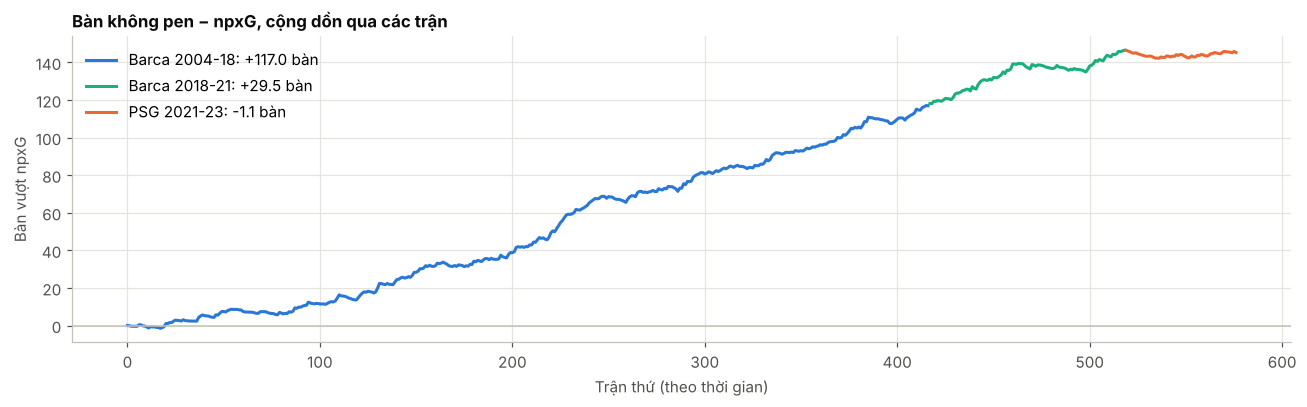

In [8]:
career = matches.sort_values("date").reset_index(drop=True)
career["cum_np_goals_minus_npxg"] = (career["non_penalty_goals"] - career["npxg"]).cumsum()

fig, ax = plt.subplots(figsize=(12, 3.8))
for period in PERIOD_ORDER:
    part = career[career["period"] == period]
    added = part["non_penalty_goals"].sum() - part["npxg"].sum()
    ax.plot(part.index, part["cum_np_goals_minus_npxg"], color=PERIOD_COLORS[period],
            label=f"{period}: {added:+.1f} bàn")
ax.axhline(0, color=AXIS_COLOR, linewidth=1)
ax.set_title("Bàn không pen − npxG, cộng dồn qua các trận")
ax.set_xlabel("Trận thứ (theo thời gian)")
ax.set_ylabel("Bàn vượt npxG")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

**Nhận xét**

- Đường cộng dồn **đi lên đều đặn suốt hơn 500 trận ở Barca**, cộng thêm khoảng +117 bàn giai đoạn 2004-18 và +29,5 bàn giai đoạn 2018-21. Khả năng ghi bàn vượt xG của Messi ổn định qua nhiều năm, không phải do vài mùa may mắn.
- Ở PSG, đường **đi ngang** (−1,1 bàn sau 58 trận).
- Nếu Messi giữ hiệu suất vượt xG như giai đoạn 2018-21 (+0,31 bàn/90'), với 4.991 phút ở Ligue 1 anh sẽ ghi thêm khoảng **17 bàn** so với xG. Thực tế là −1,1. Khoảng chênh này lớn hay nằm trong biến động ngẫu nhiên là câu hỏi của **H3**.

### 5.2 Phân phối xG của từng cú sút (không tính penalty)

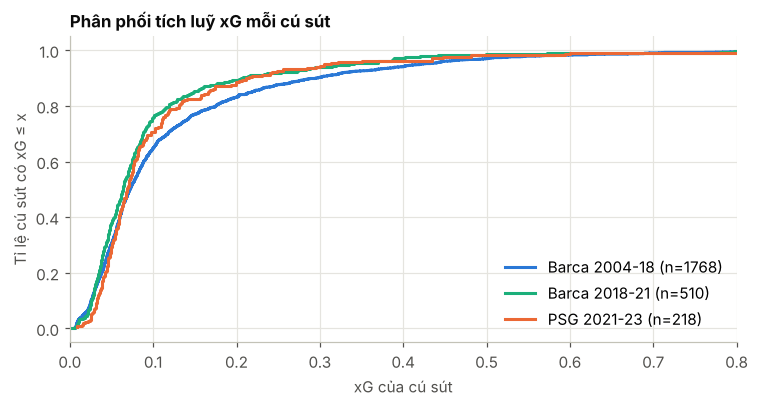

,shots,median_xg,mean_xg,pct_in_box,pct_big_chance,pct_free_kick
period,,,,,,
Barca 2004-18,1768,0.072,0.122,62.2,9.7,16.7
Barca 2018-21,510,0.064,0.097,45.5,6.1,24.3
PSG 2021-23,218,0.068,0.106,51.8,6.0,16.5


In [9]:
np_shots = shots[~shots["is_penalty"]].copy()
np_shots["in_box"] = (np_shots["x"] >= PENALTY_BOX["x_min"]) & np_shots["y"].between(
    PENALTY_BOX["y_min"], PENALTY_BOX["y_max"])
np_shots["big_chance"] = np_shots["xg"] >= 0.3

fig, ax = plt.subplots(figsize=(7, 3.8))
for period in PERIOD_ORDER:
    values = np.sort(np_shots.loc[np_shots["period"] == period, "xg"].to_numpy())
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post",
            color=PERIOD_COLORS[period], label=f"{period} (n={len(values)})")
ax.set_xlim(0, 0.8)
ax.set_title("Phân phối tích luỹ xG mỗi cú sút")
ax.set_xlabel("xG của cú sút")
ax.set_ylabel("Tỉ lệ cú sút có xG ≤ x")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

shot_quality = np_shots.groupby("period", observed=True).agg(
    shots=("xg", "size"),
    median_xg=("xg", "median"),
    mean_xg=("xg", "mean"),
    pct_in_box=("in_box", "mean"),
    pct_big_chance=("big_chance", "mean"),
    pct_free_kick=("shot_type", lambda s: (s == "Free Kick").mean()),
)
for column in ["pct_in_box", "pct_big_chance", "pct_free_kick"]:
    shot_quality[column] = (shot_quality[column] * 100).round(1)
display(shot_quality)

**Nhận xét**

- Đường của **Barca 2004-18 nằm lệch phải** so với hai giai đoạn còn lại, tức là có nhiều cú sút xG cao hơn: 62% cú sút trong vòng cấm, 9,7% là cơ hội lớn (xG ≥ 0,3).
- **Barca 2018-21 và PSG gần như trùng nhau** (trung vị xG 0,064 và 0,068; cơ hội lớn 6,1% và 6,0%). Ở PSG Messi còn sút trong vòng cấm nhiều hơn (52% so với 45%), chủ yếu vì ít đá phạt trực tiếp hơn (16,5% so với 24,3% số cú sút).
- ⇒ So với giai đoạn cuối ở Barca, **Messi ở PSG không sút từ vị trí tệ hơn**. Chất lượng cú sút giảm là thay đổi theo tuổi từ khoảng 2015, không phải do chuyển sang PSG.

### 5.3 Bản đồ cú sút (không tính penalty)

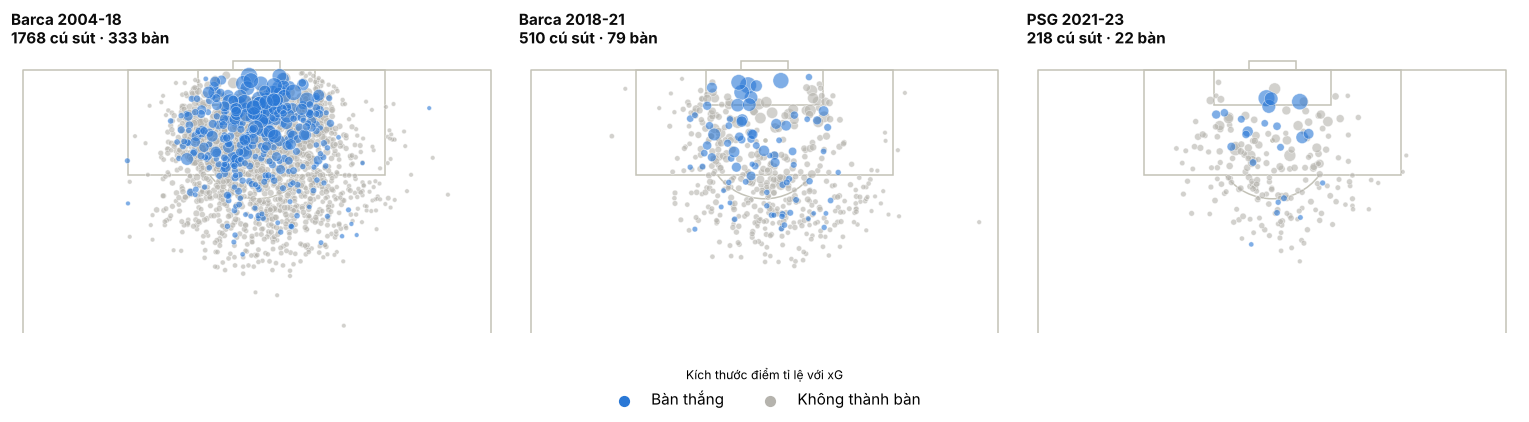

Cú sút từ ngoài vùng hiển thị (x < 75): 2


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, period in zip(axes, PERIOD_ORDER):
    period_shots = np_shots[np_shots["period"] == period]
    n_goals = int(period_shots["is_goal"].sum())
    plot_shot_map(ax, period_shots, f"{period}\n{len(period_shots)} cú sút · {n_goals} bàn")
handles = [plt.scatter([], [], s=40, color=GOAL_COLOR, label="Bàn thắng"),
           plt.scatter([], [], s=40, color=MISS_COLOR, label="Không thành bàn")]
fig.legend(handles=handles, loc="lower center", ncol=2,
           title="Kích thước điểm tỉ lệ với xG", title_fontsize=8)
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.show()

outside_view = (np_shots["x"] < PITCH_VIEW_START).sum()
print(f"Cú sút từ ngoài vùng hiển thị (x < {PITCH_VIEW_START}): {outside_view}")

### 5.4 Cơ cấu cú sút: bộ phận cơ thể, loại cú sút, kết quả

In [11]:
np_shots["body_part_group"] = np_shots["body_part"].replace({"Other": "Head/Other", "Head": "Head/Other"})
print("Bộ phận cơ thể (%):")
display(share_table(np_shots, "period", "body_part_group"))
print("Loại cú sút (%):")
display(share_table(np_shots, "period", "shot_type"))
print("Kết quả cú sút (%):")
display(share_table(np_shots, "period", "outcome"))

Bộ phận cơ thể (%):


body_part_group,Head/Other,Left Foot,Right Foot
period,,,
Barca 2004-18,6.0,81.9,12.1
Barca 2018-21,3.3,88.8,7.8
PSG 2021-23,1.8,84.9,13.3


Loại cú sút (%):


shot_type,Free Kick,Open Play
period,,
Barca 2004-18,16.7,83.3
Barca 2018-21,24.3,75.7
PSG 2021-23,16.5,83.5


Kết quả cú sút (%):


outcome,Blocked,Goal,Off T,Post,Saved,Saved Off Target,Saved to Post,Wayward
period,,,,,,,,
Barca 2004-18,24.8,18.8,23.4,3.4,27.3,0.3,0.6,1.4
Barca 2018-21,26.1,15.5,24.3,2.9,29.4,0.4,0.6,0.8
PSG 2021-23,27.5,10.1,28.0,6.4,26.6,0.5,0.5,0.5


**Nhận xét**

- Chân trái chiếm 82–89% số cú sút ở mọi giai đoạn; Messi hầu như không đánh đầu.
- **Kết quả cú sút ở PSG**: tỉ lệ thành bàn 10,1%, so với 15,5% (Barca 2018-21) và 18,8% (Barca 2004-18). Phần chênh lệch không nằm ở bị thủ môn cản phá (26,6% so với 29,4%) mà ở **sút ra ngoài** (28,0% so với 24,3%) và **trúng cột/xà** (6,4% so với 2,9%, tức 14 lần trúng khung gỗ trong 218 cú sút).
- Tỉ lệ trúng cột/xà cao gấp đôi gợi ý **một phần là kém may mắn**, nhưng cỡ mẫu nhỏ nên chỉ nên xem là gợi ý.

## 6. Tổng kết và giả thuyết cho bước kiểm định

**Các phát hiện chính**

1. Messi ở PSG ghi **0,40 bàn không pen/90'**, chưa bằng một nửa giai đoạn cuối ở Barca (0,83).
2. Anh **sút ít hơn khoảng 28%** (3,9 so với 5,5 cú/90').
3. **Chất lượng mỗi cú sút không giảm** (npxG/cú sút 0,106 so với 0,097).
4. **Khả năng ghi vượt xG biến mất**: từ +29,5 bàn trong 3 mùa cuối ở Barca xuống −1,1 bàn ở PSG. Phần này giải thích khoảng 3/4 mức sụt giảm bàn thắng.
5. Xu hướng giảm theo tuổi đã có từ trước (npxG/cú sút giảm từ khoảng mùa 2015-16), nhưng PSG vẫn thấp hơn rõ rệt so với cả giai đoạn Barca 2018-21, nên **tuổi không giải thích hết**.

**Giả thuyết cho `hypothesis_testing.py`**

Mốc so sánh chính là **Barca 2018-21 và PSG 2021-23**, để hạn chế ảnh hưởng của tuổi.

| # | Giả thuyết (H₁) | Bằng chứng trong EDA | Kiểm định gợi ý |
|---|---|---|---|
| H1 | Ở PSG Messi có **ít cơ hội tốt hơn** (npxG/90' thấp hơn) | npxG/90' 0,52 → 0,42 (−19%, hai khoảng tin cậy chồng nhau); npxG/cú sút không giảm | Bootstrap khoảng tin cậy cho chênh lệch npxG/90'; Mann–Whitney trên xG từng cú sút |
| H2 | Ở PSG Messi **sút ít hơn** (cú sút/90' thấp hơn) | 5,48 → 3,93 (−28%) | Hồi quy Poisson/Negative Binomial: `shots ~ period`, offset `log(minutes)` |
| H3 | Ở PSG Messi **dứt điểm kém hơn** so với xG | Bàn không pen − npxG: +29,5 → −1,1 | Hồi quy logistic trên từng cú sút: `goal ~ logit(xg) + period`; mô hình xG riêng của Messi huấn luyện ở Barca, dự đoán ở PSG |
| H4 | Mức giảm ở PSG **không chỉ do tuổi** | PSG thấp hơn cả Barca 2018-21 | Hồi quy Poisson trên mọi trận: `np_goals ~ age + age² + is_psg`, offset `log(minutes)`; hệ số `is_psg` có ý nghĩa nghĩa là còn tác động ngoài tuổi |

**Lưu ý khi kiểm định**

- Mẫu PSG nhỏ (58 trận, 218 cú sút), nên lực kiểm định thấp. Kết quả "không có ý nghĩa" ở H1 không chứng minh hai giai đoạn giống nhau; hãy báo cáo khoảng tin cậy của chênh lệch.
- Kèm **effect size** (tỉ số tỉ lệ, chênh lệch bàn/90') bên cạnh p-value. Nếu muốn chặt chẽ hơn, hiệu chỉnh Holm cho 4 kiểm định.
- Các câu hỏi phụ đã bỏ khỏi notebook (số cú sút và bàn thắng trong cùng một trận, sân nhà/sân khách, khung phút ghi bàn) nằm ngoài câu hỏi chính. Có thể nhắc tới ở phần **Hướng mở rộng**.